In [16]:
%matplotlib widget
import importlib
import numpy as np
import scipy as sc
from mpl_toolkits.mplot3d import Axes3D
import os
import matplotlib.pyplot as plt
import time

#Mes imports

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Simulations')
import nano_objects
importlib.reload(nano_objects)
from nano_objects import *

os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Pump_probe\Traces_treatment')
import P_and_P_func
importlib.reload(P_and_P_func)
from P_and_P_func import *



os.chdir(r'C:\Users\nberr\Documents\Code\python\Modules')
import Slider_plot
importlib.reload(Slider_plot)
from Slider_plot import *
import Slider_plot_v2
importlib.reload(Slider_plot_v2)
from Slider_plot_v2 import *

from matplotlib.widgets import Slider, Button


## Definition of oscillating functions

In [17]:

def Osc4(t, A1,tau1, T1, phi1,A2,tau2, T2, phi2,A3,tau3, T3, phi3,A4,tau4, T4, phi4):
    return   A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1) + \
            A2*np.exp(-t/tau2)*np.sin(2*np.pi/T2*t+phi2) + \
            A3*np.exp(-t/tau3)*np.sin(2*np.pi/T3*t+phi3) + \
            A4*np.exp(-t/tau4)*np.sin(2*np.pi/T4*t+phi4) 
def Osc3(t, A1,tau1, T1, phi1,A2,tau2, T2, phi2,A3,tau3, T3, phi3):
    return   A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1) + \
            A2*np.exp(-t/tau2)*np.sin(2*np.pi/T2*t+phi2) + \
            A3*np.exp(-t/tau3)*np.sin(2*np.pi/T3*t+phi3)
def Osc2(t, A1,tau1, T1, phi1,A2,tau2, T2, phi2):
    return   A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1) + \
            A2*np.exp(-t/tau2)*np.sin(2*np.pi/T2*t+phi2)
def Osc1(t, A1,tau1, T1, phi1):
    return   A1*np.exp(-t/tau1)*np.sin(2*np.pi/T1*t+phi1)


Get data

In [18]:
def plot_2_acoustic_modes(arg_cte, arg_var, labels=False) :

    A_1, tau_1, T_1, phi_1 = arg_var[0:4]
    A_2, tau_2, T_2, phi_2 = arg_var[4:8]



    Time = arg_cte[0]

    Labels = []
    if labels :
        Labels.append(Label_info(label = 'Total acoustic signal', linestyle = '-', color = 'red'))

    return(Time, [Osc2(Time, A_1, tau_1, T_1, phi_1, A_2, tau_2, T_2, phi_2)], Labels)


def plot_3_acoustic_modes(arg_cte, arg_var, labels=False) :

    A_1, tau_1, T_1, phi_1 = arg_var[0:4]
    A_2, tau_2, T_2, phi_2 = arg_var[4:8]

    A_3, tau_3, T_3, phi_3 = arg_var[8:12]




    Time = arg_cte[0]

    Labels = []
    if labels :
        Labels.append(Label_info(label = 'Total acoustic signal', linestyle = '-', color = 'red'))

    return(Time, [Osc3(Time, A_1, tau_1, T_1, phi_1, A_2, tau_2, T_2, phi_2, A_3, tau_3, T_3, phi_3)], Labels)


## Get experimental data

In [19]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND lithography\Silica\2026-06 - first sample\Array 1\D_200_col4_ND2'
dir_name = r'12-Oct-2026_PaP_Pp15uW_ldap455nm_ldas910nm'



dir_name += '_treated'
filename='Trace'

filename = filename + '_acoustic_fitted'

Trace = get_PaP_dataset(dir_root + '\\' + dir_name, filename)

Figure(900x900)
Axes(0.125,0.11;0.775x0.77)
['$A_1$', '$\\tau_1$', '$T_1$', '$phi_1$', '$A_2$', '$\\tau_2$', '$T_2$', '$phi_2$', '$A_3$', '$\\tau_3$', '$T_3$', '$phi_3$']


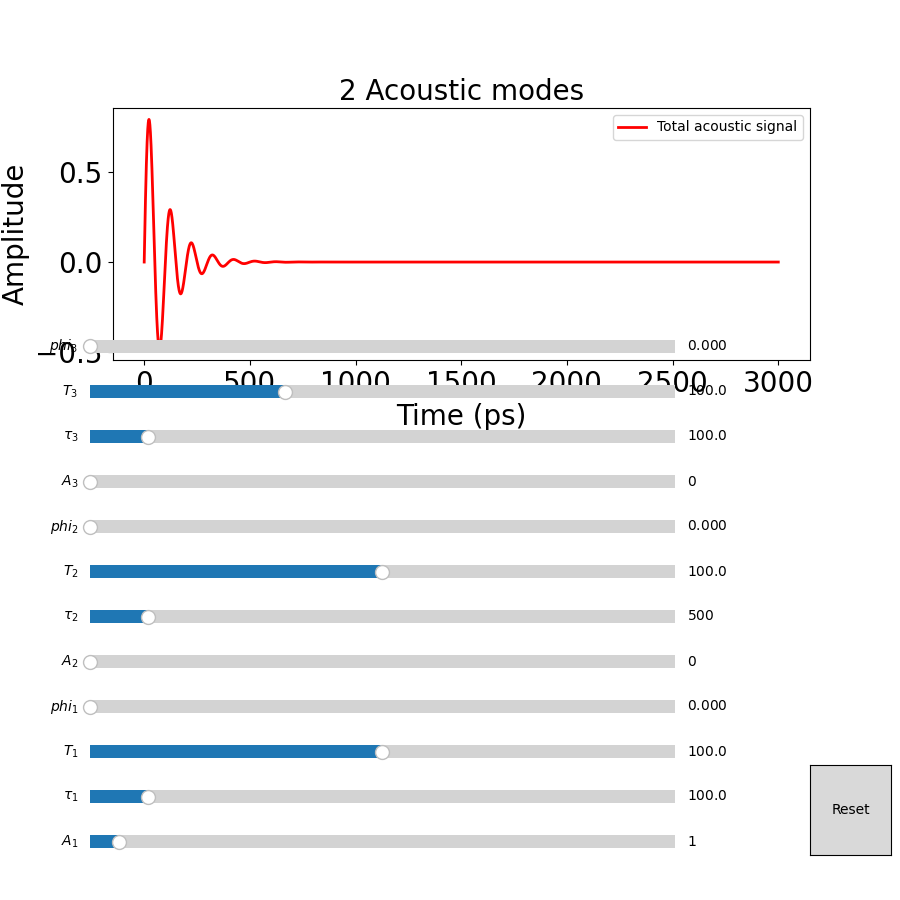

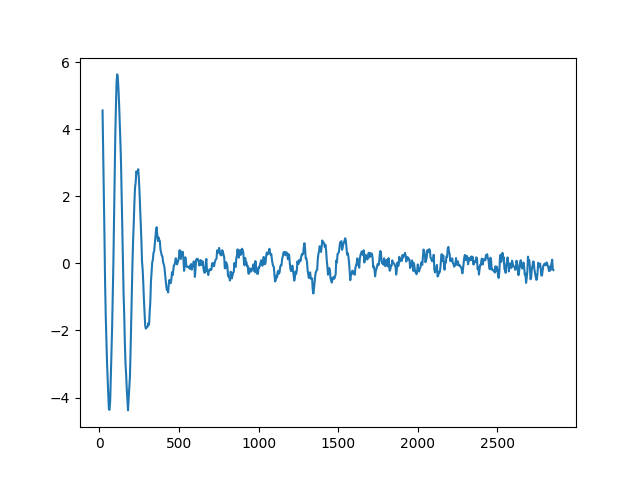

In [20]:
Acoustic_modes = Param_slider()
Acoustic_modes.add_param(r'$A_1$', 1, 0, 20)
Acoustic_modes.add_param(r'$\tau_1$', 100, 0.1, 1000)
Acoustic_modes.add_param(r'$T_1$', 100, 0.1, 200)
Acoustic_modes.add_param(r'$phi_1$', 0, 0, 2*np.pi)

Acoustic_modes.add_param(r'$A_2$', 0, 0, 20)
Acoustic_modes.add_param(r'$\tau_2$', 500, 0.1, 5000)
Acoustic_modes.add_param(r'$T_2$', 100, 0.1, 200)
Acoustic_modes.add_param(r'$phi_2$', 0, 0, 2*np.pi)


Acoustic_modes.add_param(r'$A_3$', 0, 0, 20)
Acoustic_modes.add_param(r'$\tau_3$', 100, 0.1, 1000)
Acoustic_modes.add_param(r'$T_3$', 100, 0.1, 300)
Acoustic_modes.add_param(r'$phi_3$', 0, 0, 2*np.pi)



Time = np.linspace(0, 3000, 5000)



fig, ax = plt.subplots()
ax.plot(Trace.delay, Trace.DTT_acoustic*1e5)


Acoustic_modes.plot(plot_3_acoustic_modes, [Time], titre='2 Acoustic modes', xtitle='Time (ps)', ytitle='Amplitude', figsize=(9,9))



#### Paramètres pour reproduire nos observations rapidement

# A1 = 10, tau1 = 100, T1 = 32ps, phi1=0  /  A2 = 1, tau2 = 1000 ps, T2 = 30ps, phi2=0

# Valeurs cohérente avec l'étude du 19 Décembre 2025
# A1 = 10, tau1 = 161, T1 = 45.5ps, phi1=0  /  A2 = 0.5, tau2 = 850 ps, T2 = 44.1 ps, phi2=0